# 📘 13 — Statistics
*Part of the Full Stack Data Science & AI booklet. Run cells top to bottom (Shift + Enter). Install libraries first: `pip install -r ../requirements.txt`.*

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import os, sys, math, random, json, time, copy, warnings
from IPython.display import display
warnings.filterwarnings("ignore")

# 1️⃣4️⃣ Statistics for Data Science
Statistics = collecting, summarising and drawing conclusions from data.
- **Population**: everyone. **Sample**: the part you actually measure.
- **Descriptive**: describe the data you have. **Inferential**: make conclusions about the population from a sample.

## 14.1 Descriptive statistics
| Type | Measures |
|---|---|
| Central tendency | mean, median, mode |
| Spread | range, variance, std deviation, IQR |
| Shape | skewness, kurtosis |
| Position | percentiles, quartiles, z-score |

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

data = pd.Series([12, 15, 14, 10, 18, 20, 15, 13, 100])      # 100 is an outlier
print("Mean:", data.mean(), "| Median:", data.median(), "| Mode:", data.mode()[0])
print("Range:", data.max() - data.min())
print("Variance (sample):", round(data.var(), 2), "| Std:", round(data.std(), 2))
print("Q1, Q3, IQR:", data.quantile(.25), data.quantile(.75), data.quantile(.75) - data.quantile(.25))
print("Skewness:", round(data.skew(), 2), "| Kurtosis:", round(data.kurt(), 2))
print("Mean is pulled by the outlier; median is robust -> prefer median for skewed data.")

z = (data - data.mean()) / data.std()          # z-score: how many std from the mean
print("z-scores > 2:", data[abs(z) > 2].tolist())
print(data.describe())

Mean: 24.11111111111111 | Median: 15.0 | Mode: 15
Range: 90
Variance (sample): 818.86 | Std: 28.62
Q1, Q3, IQR: 13.0 18.0 5.0
Skewness: 2.94 | Kurtosis: 8.72
Mean is pulled by the outlier; median is robust -> prefer median for skewed data.
z-scores > 2: [100]
count      9.000000
mean      24.111111
std       28.615749
min       10.000000
25%       13.000000
50%       15.000000
75%       18.000000
max      100.000000
dtype: float64


#### 🔍 How it works
- **Mean** is dragged by outliers (the `100`); **median** (middle value) is robust → use median for skewed data (salaries, house prices).
- **Std** = typical distance from the mean; **variance** = std²; **IQR** = Q3 − Q1 = spread of the middle 50%; **skew** > 0 means a long right tail.
- **z-score** `(x − mean)/std` = how many standard deviations a point is from average; |z| > 2–3 is usually an outlier.
#### 💼 Where it's used
Anomaly detection (fraud, sensor faults), feature scaling for ML, reporting averages correctly (mean vs median).

**Formulas (in words)**
- Mean = sum ÷ count
- Variance = average of squared distance from the mean (÷ n-1 for a sample)
- Std = √variance
- z = (x − mean) ÷ std
- Correlation *r* is between −1 and +1 (0 = no linear relation)

In [3]:
students = pd.read_csv("data/students.csv").dropna()
print("Correlation study_hours vs marks:", round(students.study_hours.corr(students.marks), 3))
print("Covariance:", round(students.study_hours.cov(students.marks), 2))
print(students[["study_hours", "attendance", "marks"]].corr(method="spearman").round(2))   # rank-based

Correlation study_hours vs marks: 0.872
Covariance: 29.58
             study_hours  attendance  marks
study_hours         1.00       -0.18   0.88
attendance         -0.18        1.00   0.11
marks               0.88        0.11   1.00


#### 🔍 How it works
- **Correlation (r)**: −1 to +1, strength of a *straight-line* relation. **Spearman** uses ranks (works for curved but always-rising relations and resists outliers). **Covariance** shows direction but depends on units.
- ⚠️ **Correlation ≠ causation**: ice-cream sales and drowning both rise in summer.

## 14.2 Probability & distributions
- **Probability** = favourable outcomes ÷ total outcomes.
- **Normal (bell curve)**: 68% of values within 1σ, 95% within 2σ, 99.7% within 3σ.
- **Binomial**: number of successes in n tries. **Poisson**: events per time. **Uniform**: all equally likely.

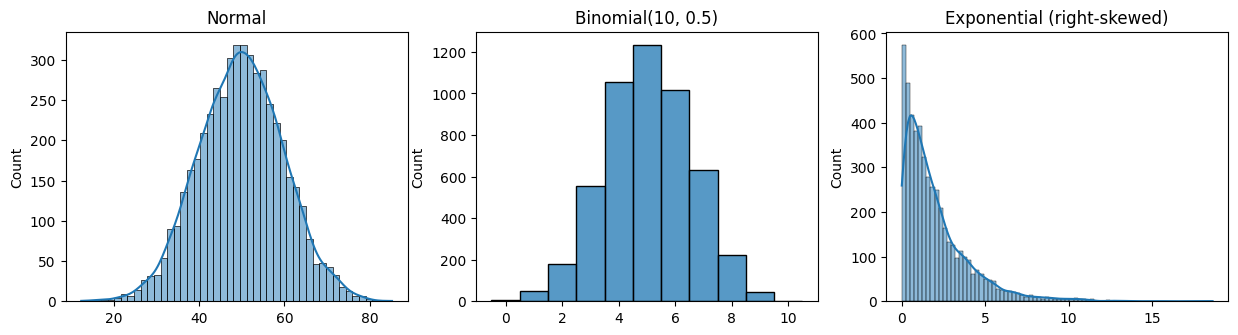

P(X < 60) for N(50,10): 0.841
P(40 < X < 60): 0.683
Score at 90th percentile: 62.8
P(exactly 3 heads in 5 tosses): 0.312
P(disease | positive test): 0.161 <- only ~16% even with a 95% test!


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
norm = np.random.normal(50, 10, 5000); sns.histplot(norm, kde=True, ax=ax[0]).set_title("Normal")
sns.histplot(np.random.binomial(10, 0.5, 5000), discrete=True, ax=ax[1]).set_title("Binomial(10, 0.5)")
sns.histplot(np.random.exponential(2, 5000), kde=True, ax=ax[2]).set_title("Exponential (right-skewed)")
plt.show()

print("P(X < 60) for N(50,10):", round(stats.norm.cdf(60, 50, 10), 3))
print("P(40 < X < 60):", round(stats.norm.cdf(60, 50, 10) - stats.norm.cdf(40, 50, 10), 3))
print("Score at 90th percentile:", round(stats.norm.ppf(0.9, 50, 10), 1))
print("P(exactly 3 heads in 5 tosses):", round(stats.binom.pmf(3, 5, .5), 3))

# Conditional probability & Bayes: P(A|B) = P(B|A)P(A) / P(B)
p_disease, sens, false_pos = 0.01, 0.95, 0.05
p_pos = sens * p_disease + false_pos * (1 - p_disease)
print("P(disease | positive test):", round(sens * p_disease / p_pos, 3), "<- only ~16% even with a 95% test!")

#### 🔍 How it works
- **Normal distribution** (bell curve): 68% of values within 1σ, 95% within 2σ. `stats.norm.cdf(x, mean, std)` = P(X < x); `ppf(p)` = the value at percentile p (the inverse).
- **Binomial** counts successes in n tries; `binom.pmf(3, 5, .5)` = P(exactly 3 heads in 5).
- **Bayes' rule** updates a belief: even with a 95% accurate test, a rare disease (1%) means most positives are false alarms (**base-rate fallacy**) — a famous interview/stat puzzle.
#### 💼 Where it's used
Quality control, risk modelling, medical test interpretation, spam filters (Naive Bayes).

## 14.3 Sampling & Central Limit Theorem (CLT)
> No matter how weird the population is, the **averages of many samples** form a bell curve.

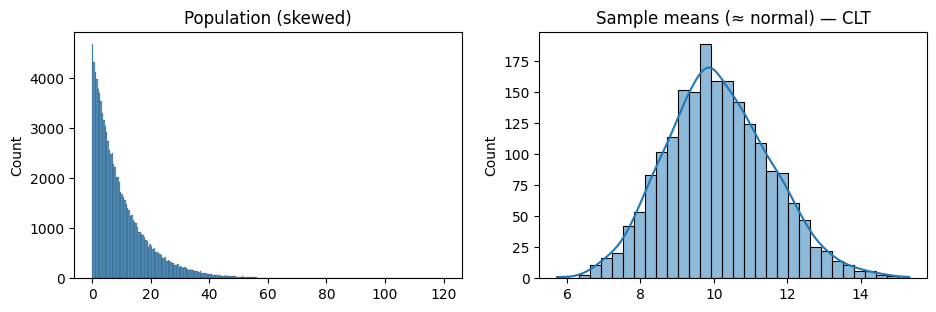

Population mean: 10.09 | Mean of sample means: 10.13


In [5]:
population = np.random.exponential(scale=10, size=100_000)          # skewed!
means = [np.random.choice(population, 50).mean() for _ in range(2000)]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
sns.histplot(population, ax=ax[0]).set_title("Population (skewed)")
sns.histplot(means, kde=True, ax=ax[1]).set_title("Sample means (≈ normal) — CLT")
plt.show()
print("Population mean:", round(population.mean(), 2), "| Mean of sample means:", round(np.mean(means), 2))

#### 🔍 How it works
- We draw 2,000 random samples of size 50 from a **skewed** population and record each sample's mean. The histogram of those means is **bell-shaped** → this is the **Central Limit Theorem**: averages become normal regardless of the original shape.
#### 💼 Where it's used
CLT is **why** t-tests, confidence intervals and A/B tests work even when raw data isn't normal.

## 14.4 Inferential statistics
### Confidence interval & hypothesis testing
- **Confidence interval (CI)**: a range likely to contain the true population value (95% CI is common).
- **Hypothesis test**: H₀ (null) = "no effect". H₁ = "there is an effect".
- **p-value**: chance of seeing data this extreme *if H₀ were true*. If **p < 0.05**, we reject H₀.
- **Type I error**: reject a true H₀ (false alarm). **Type II**: miss a real effect.

| Test | Use when |
|---|---|
| z-test | big sample (n>30), known σ |
| one-sample t-test | compare a sample mean with a known value |
| two-sample t-test | compare 2 group means |
| paired t-test | same people before/after |
| ANOVA | compare 3+ group means |
| chi-square | two categorical variables related? |
| Shapiro-Wilk | is data normal? |

In [6]:
sample = students.marks
ci = stats.t.interval(0.95, len(sample) - 1, loc=sample.mean(), scale=stats.sem(sample))
print("Mean marks:", round(sample.mean(), 2), "| 95% CI:", np.round(ci, 2))

# 1) One-sample t-test: is average marks different from 60?
t, p = stats.ttest_1samp(sample, 60); print(f"1-sample t-test: t={t:.2f}, p={p:.4f}")

# 2) Two-sample t-test: do boys and girls score differently?
m, f = students[students.gender == "M"].marks, students[students.gender == "F"].marks
t, p = stats.ttest_ind(m, f); print(f"2-sample t-test: t={t:.2f}, p={p:.4f} ->", "significant" if p < .05 else "no significant difference")

# 3) ANOVA: do the 4 branches differ?
groups = [g.marks.values for _, g in students.groupby("branch")]
F, p = stats.f_oneway(*groups); print(f"ANOVA: F={F:.2f}, p={p:.4f}")

# 4) Chi-square: is survival related to sex?
pas = pd.read_csv("data/passengers.csv")
chi, p, dof, _ = stats.chi2_contingency(pd.crosstab(pas.sex, pas.survived)); print(f"Chi-square: chi2={chi:.1f}, p={p:.2e} -> related" if p < .05 else "not related")

# 5) Normality & correlation significance
print("Shapiro (normality) p =", round(stats.shapiro(sample)[1], 4))
r, p = stats.pearsonr(students.study_hours, students.marks); print(f"Pearson r={r:.2f}, p={p:.2e}")

Mean marks: 75.44 | 95% CI: [71.68 79.2 ]
1-sample t-test: t=8.24, p=0.0000
2-sample t-test: t=1.39, p=0.1705 -> no significant difference
ANOVA: F=0.64, p=0.5899
Chi-square: chi2=90.7, p=1.64e-21 -> related
Shapiro (normality) p = 0.1503
Pearson r=0.87, p=4.62e-18


#### 🔍 How to read the results
- **Confidence interval:** a range that would contain the true mean in 95% of repeated studies.
- **p-value:** probability of results this extreme **if there were no real effect**. `p < 0.05` → reject the null hypothesis (call the result *statistically significant*). It does **not** tell you the effect is big or important.
- **Which test:** 1 sample vs known value → `ttest_1samp`; 2 groups → `ttest_ind`; 3+ groups → `f_oneway` (ANOVA); two categories → `chi2_contingency`; normality → `shapiro`.
#### 💼 Where it's used
**A/B testing** ("is the new checkout page really better?"), clinical trials, policy impact, marketing experiments.

## 14.5 Advanced statistics: A/B testing, effect size, bootstrap, outliers

In [7]:
# A/B test: conversion of old page vs new page
a_conv, a_n, b_conv, b_n = 120, 1000, 150, 1000
p_pool = (a_conv + b_conv) / (a_n + b_n)
z = (b_conv / b_n - a_conv / a_n) / np.sqrt(p_pool * (1 - p_pool) * (1 / a_n + 1 / b_n))
print(f"A/B test z={z:.2f}, p={2 * (1 - stats.norm.cdf(abs(z))):.4f}")

# Effect size (Cohen's d): how BIG is the difference, not just is it real
d = (m.mean() - f.mean()) / np.sqrt((m.var() + f.var()) / 2); print("Cohen's d:", round(d, 2))

# Bootstrap: CI without formulas
boot = [np.random.choice(sample, len(sample)).mean() for _ in range(3000)]
print("Bootstrap 95% CI:", np.percentile(boot, [2.5, 97.5]).round(2))

# Non-parametric alternative when data is not normal
print("Mann-Whitney U p =", round(stats.mannwhitneyu(m, f).pvalue, 4))
# Multiple testing warning: run 20 tests at p<0.05 and ~1 will be a false positive (use Bonferroni: p < 0.05/20)

A/B test z=1.96, p=0.0496
Cohen's d: 0.37
Bootstrap 95% CI: [72.   79.08]
Mann-Whitney U p = 0.106


#### 🔍 How it works
- **A/B test z-score:** compares two conversion rates using the pooled proportion; `2 × (1 − cdf(|z|))` converts z to a two-sided p-value.
- **Cohen's d** = difference ÷ pooled std → tells you **how big** the difference is (0.2 small, 0.5 medium, 0.8 large). With huge samples even a tiny, useless difference is "significant".
- **Bootstrap** = resample your own data thousands of times to get a CI with no formula. **Mann-Whitney U** is the test to use when data isn't normal.
- **Multiple testing:** run 20 tests at 5% and one will "succeed" by luck — correct with Bonferroni (`0.05 / number_of_tests`).

### 🧪 Practice (Section 14)
1. Compute mean/median/std of `fare` and explain the skew. 2. Test whether 1st-class fares differ from 3rd-class (t-test). 3. Build a 99% CI for age. 4. Is `embarked` related to `survived` (chi-square)?